# Sensitivities and hedging geometry

Family 23. All derivatives specify which input is bumped and its unit. A
hedge minimizes residual exposure in supplied risk coordinates; it is not an
optimal trading strategy or a promise of stable realized P&L.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import contracts as ct, curves as cv, pricing as pr
rng = np.random.default_rng(2300)
ref, expiry = '2026-01-01', '2027-01-01'
discount, dividend = cv.flat_curve(ref, .04), cv.flat_curve(ref, .01)
model = pr.BlackScholesModel(100., discount, dividend, .2)
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Analytic delta and finite-difference step choice

Central differences trade truncation error against cancellation. The test
holds dividend yield, financing and implied volatility fixed when spot changes.

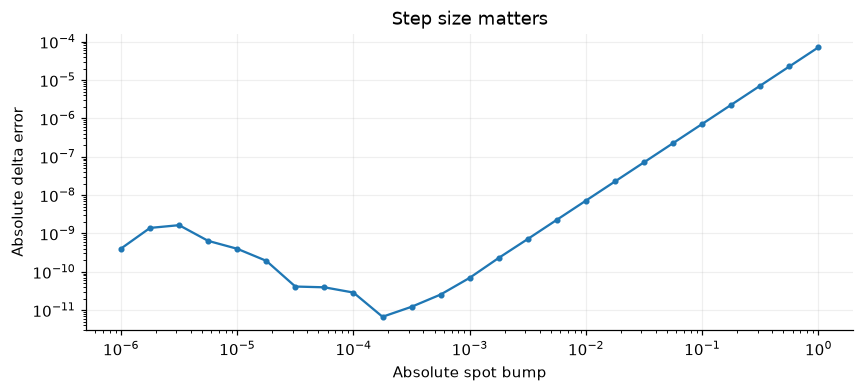

,delta,gamma,vega,theta,rho,dividendRho
0,0.592749,0.019141,38.28207,-5.233665,49.955171,-59.27491


In [2]:
from dataclasses import replace
from convexity.math import sensitivities as se
contract=ct.VanillaContract(100,ct.Exercise('european',(expiry,)))
def value(spot):
    return pr.price(pr.PricingProblem(contract,replace(model,spot=spot),ref),pr.VanillaEngine()).value
analytic=pr.price(pr.PricingProblem(contract,model,ref),pr.VanillaEngine())
steps=np.logspace(-6,0,25)
estimates=np.array([(value(100+h)-value(100-h))/(2*h) for h in steps])
plt.loglog(steps,np.maximum(np.abs(estimates-analytic.greeks['delta']),1e-16),marker='.')
plt.xlabel('Absolute spot bump');plt.ylabel('Absolute delta error');plt.title('Step size matters');plt.show()
display(pd.DataFrame([dict(analytic.greeks)]))

## Cross-Greeks have two input units

The Hessian below uses spot units and decimal volatility units. Its mixed
entry is the sensitivity of delta to volatility; comparing raw entries across
coordinates requires attention to their scales.

,Spot,Decimal vol
Spot,0.019141,-0.095705
Decimal vol,-0.095705,2.392630


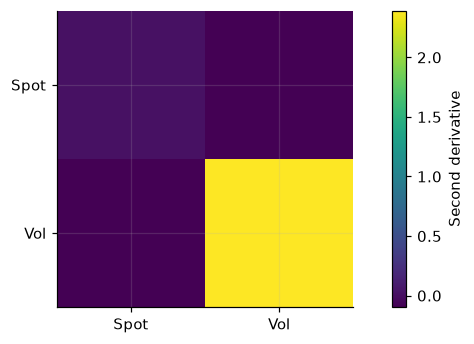

In [3]:
def price_at(x):
    changed=replace(model,spot=x[0],volatility=x[1])
    return pr.price(pr.PricingProblem(contract,changed,ref),pr.VanillaEngine()).value
risk=se.bump_sensitivities(price_at,[100.,.2],steps=[.01,1e-4])
display(pd.DataFrame(risk['hessian'],index=['Spot','Decimal vol'],columns=['Spot','Decimal vol']))
plt.imshow(risk['hessian']);plt.xticks([0,1],['Spot','Vol']);plt.yticks([0,1],['Spot','Vol']);plt.colorbar(label='Second derivative');plt.show()

## Exposure matrices, bounds and nullspaces

Rows of A are risk factors and columns are hedge instruments. The target is an
existing portfolio exposure, so A h + target is the residual. Nonnegative
holdings restrict the feasible risk geometry.

,Instrument 1,Instrument 2,Instrument 3
Unconstrained,-1.666667e+00,1.333333,-3.333333e-01
Long only,2.322913e-19,1.000000,6.875598e-20
Zero net units,-1.000000e+00,2.000000,-1.000000e+00


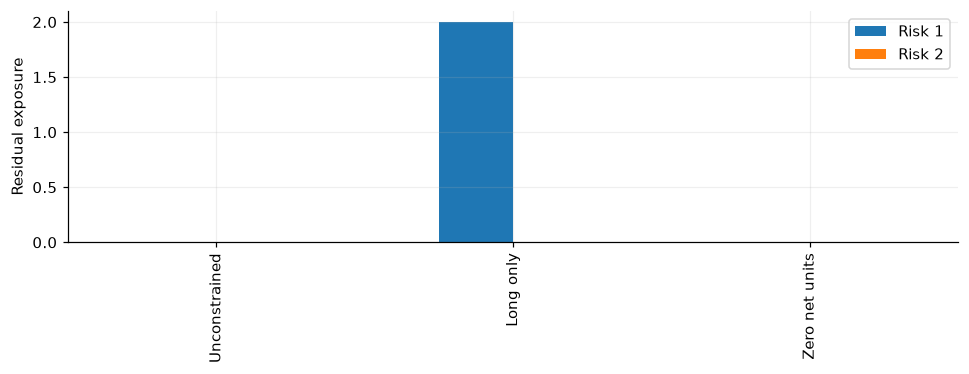

Exposure nullspace basis: [-0.57735027 -0.57735027  0.57735027]


In [4]:
A=np.array([[1.,0.,1.],[0.,1.,1.]])
target=np.array([2.,-1.])
free=se.hedge(A,target)
bounded=se.hedge(A,target,lower=0)
budgeted=se.hedge(A,target,equality=[[1.,1.,1.]],equality_target=[0.])
display(pd.DataFrame([r.holdings for r in [free,bounded,budgeted]],index=['Unconstrained','Long only','Zero net units'],columns=['Instrument 1','Instrument 2','Instrument 3']))
pd.DataFrame([r.residual_exposure for r in [free,bounded,budgeted]],index=['Unconstrained','Long only','Zero net units'],columns=['Risk 1','Risk 2']).plot.bar()
plt.ylabel('Residual exposure');plt.tight_layout();plt.show()
print('Exposure nullspace basis:',free.nullspace.ravel())

## Scope of the evidence

These are generated-data experiments under the stated models, not market forecasts or universal model rankings. Numerical errors, backend restrictions and measure assumptions are documented in the [financial catalog](../financial_mathematics.md) and [QA record](../financial_qa.md). Automated adversarial checks live in `tests/math/finance/`.